# Drought model results

Charts for the two drought models. Run the models first (see `HOW_TO_USE.md`), then **Run All** here.

- **Part 1:** Drought Monitor level per planning region (`python -m drought_rf.usdm ...`, results in `outputs/usdm/`)
- **Part 2:** Streamflow drought at stream gauges (`python -m drought_rf --data data/raw ...`, results in `outputs/`)

Change `REGION` and `LEAD` in the next cell to look at a different region or forecast horizon.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

USDM_OUT = Path("outputs/usdm")   # where python -m drought_rf.usdm wrote its files
GAUGE_OUT = Path("outputs")       # where python -m drought_rf wrote its files
REGION = "Capitol"                # any of the 9 planning regions
LEAD = 2                          # weeks ahead: 0, 1, 2 or 4

LEVELS = ["None", "D0", "D1", "D2+"]
NAMES = {"persistence": "Same as this week", "climatology": "Usual for this month",
         "rf_weather": "Forest: weather only", "rf_weather_plus_now": "Forest: weather + current level"}
COLORS = {"persistence": "#9aa0a6", "climatology": "#c9c3b5", "rf_weather": "#7fb3d5", "rf_weather_plus_now": "#1f5f8b"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

## Part 1: Drought Monitor level per planning region

In [2]:
S = pd.read_csv(USDM_OUT / "summary.csv")
P = pd.read_csv(USDM_OUT / "predictions.csv", parse_dates=["date", "target_date"])
print(f"{len(P):,} predictions, test years {P.test_year.min()}-{P.test_year.max()}, regions: {P.site.nunique()}")
S.round(3)

30,060 predictions, test years 2010-2025, regions: 9


,lead_weeks,model,n,exact_level,within_one_level,kappa_weighted,d1plus_hit_rate,d1plus_false_alarm,d1plus_brier,onsets,onset_caught,onset_false_alarm_rate
0,0,climatology,7515,0.659,0.838,0.000,0.000,NaN,0.162,0,NaN,0.000
1,0,persistence,7515,1.000,1.000,1.000,1.000,0.000,0.000,0,NaN,0.000
2,0,rf_weather,7515,0.685,0.921,0.499,0.405,0.421,0.101,0,NaN,0.168
3,0,rf_weather_plus_now,7515,0.962,1.000,0.973,0.999,0.001,0.011,0,NaN,0.000
4,1,climatology,7515,0.658,0.838,0.000,0.000,NaN,0.162,99,0.000,0.000
5,1,persistence,7515,0.917,0.999,0.943,0.919,0.081,0.026,99,0.000,0.000
6,1,rf_weather,7515,0.680,0.916,0.493,0.403,0.422,0.100,99,0.646,0.145
7,1,rf_weather_plus_now,7515,0.859,0.996,0.896,0.884,0.101,0.037,99,0.556,0.028
8,2,climatology,7515,0.657,0.838,0.000,0.000,NaN,0.162,181,0.000,0.000
9,2,persistence,7515,0.848,0.993,0.888,0.851,0.149,0.048,181,0.000,0.000


### How often each model gets the exact level right

"Same as this week" is hard to beat because Drought Monitor levels change slowly. The gap shrinks as you look further ahead.

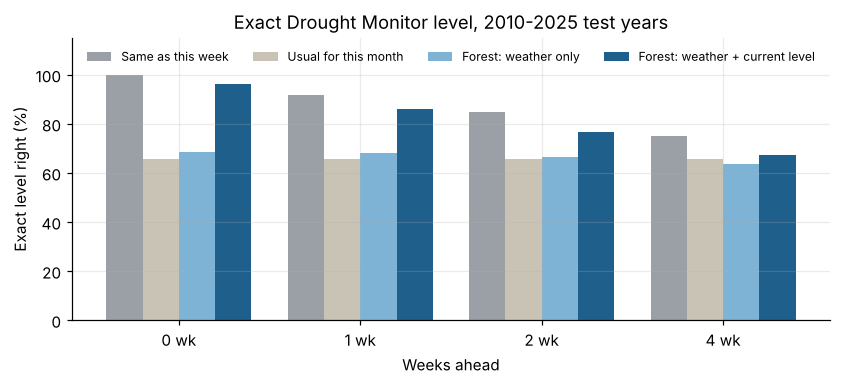

In [3]:
models = list(NAMES)
leads = sorted(S.lead_weeks.unique())
fig, ax = plt.subplots(figsize=(8, 3.6))
w = 0.2
for i, m in enumerate(models):
    v = S[S.model == m].set_index("lead_weeks").loc[leads, "exact_level"]
    ax.bar(np.arange(len(leads)) + (i - 1.5) * w, v * 100, w, label=NAMES[m], color=COLORS[m])
ax.set_xticks(range(len(leads)), [f"{l} wk" for l in leads]); ax.set_xlabel("Weeks ahead")
ax.set_ylabel("Exact level right (%)"); ax.set_ylim(0, 115); ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center")
ax.set_title("Exact Drought Monitor level, 2010-2025 test years"); plt.tight_layout(); plt.show()

### Warning of new droughts

A "new drought" is a week where a region is *not* in D1 now but is at D1 or worse by the target week. Copying this week can never catch one. Left: share caught. Right: share of quiet weeks with a false alarm (lower is better).

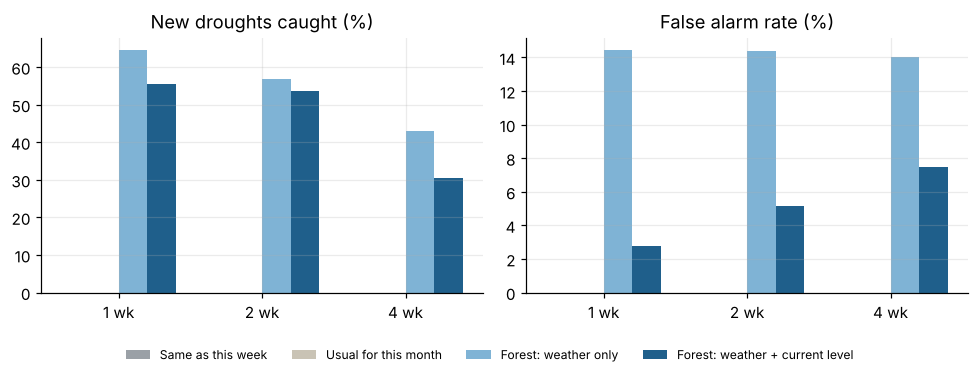

In [4]:
sub = S[S.lead_weeks > 0]
leads2 = sorted(sub.lead_weeks.unique())
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, col, title in [(axes[0], "onset_caught", "New droughts caught (%)"), (axes[1], "onset_false_alarm_rate", "False alarm rate (%)")]:
    for i, m in enumerate(models):
        v = sub[sub.model == m].set_index("lead_weeks").loc[leads2, col]
        ax.bar(np.arange(len(leads2)) + (i - 1.5) * w, v * 100, w, label=NAMES[m], color=COLORS[m])
    ax.set_xticks(range(len(leads2)), [f"{l} wk" for l in leads2]); ax.set_title(title)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False, fontsize=8)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

### Predicted vs actual over time for one region

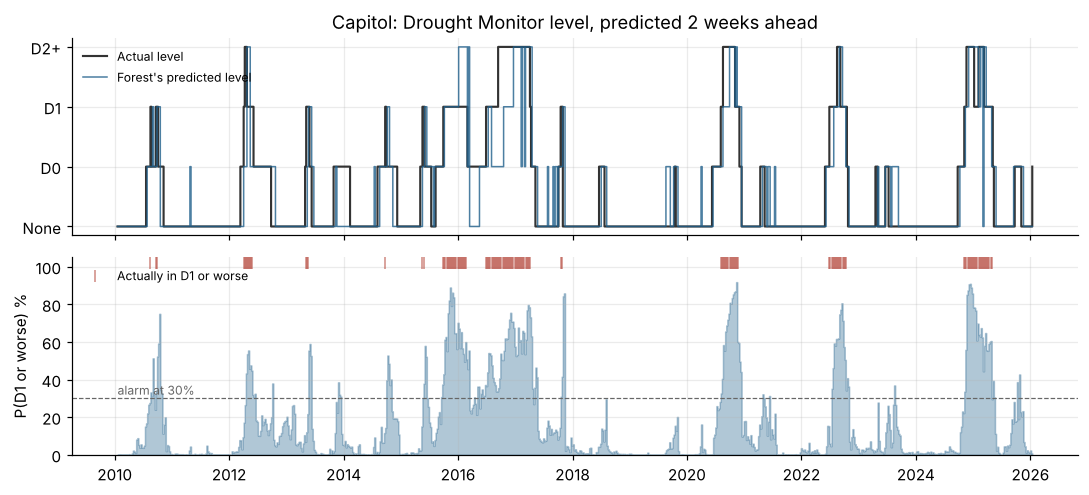

In [5]:
g = P[(P.site == REGION) & (P.lead_weeks == LEAD)].sort_values("target_date")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
a1.step(g.target_date, g.y, where="post", color="#333", lw=1.4, label="Actual level")
a1.step(g.target_date, g.rf_weather_plus_now, where="post", color=COLORS["rf_weather_plus_now"], lw=1, alpha=.8, label="Forest's predicted level")
a1.set_yticks(range(4), LEVELS); a1.legend(frameon=False, fontsize=8, loc="upper left")
a1.set_title(f"{REGION}: Drought Monitor level, predicted {LEAD} weeks ahead")
a2.fill_between(g.target_date, g.rf_weather_plus_now_p_d1plus * 100, color=COLORS["rf_weather_plus_now"], alpha=.35, step="post")
dr = g[g.y >= 2]
a2.plot(dr.target_date, np.full(len(dr), 102), color="#b03a2e", lw=0, marker="|", ms=8, alpha=.6, label="Actually in D1 or worse")
a2.axhline(30, color="#666", ls="--", lw=.8); a2.text(g.target_date.iloc[0], 32, "alarm at 30%", fontsize=8, color="#666")
a2.set_ylabel("P(D1 or worse) %"); a2.set_ylim(0, 105); a2.legend(frameon=False, fontsize=8, loc="upper left")
a2.xaxis.set_major_locator(mdates.YearLocator(2)); a2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

### Where the forest gets it wrong (all regions)

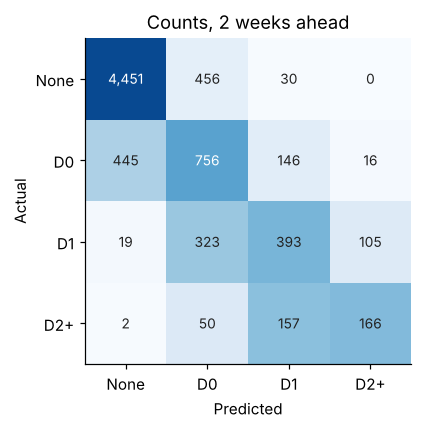

In [6]:
from sklearn.metrics import confusion_matrix
g = P[P.lead_weeks == LEAD]
cm = confusion_matrix(g.y, g.rf_weather_plus_now, labels=range(4))
share = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(share, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if share[i, j] > .5 else "#222", fontsize=9)
ax.set_xticks(range(4), LEVELS); ax.set_yticks(range(4), LEVELS)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"Counts, {LEAD} weeks ahead")
plt.tight_layout(); plt.show()

### What the forest relies on most

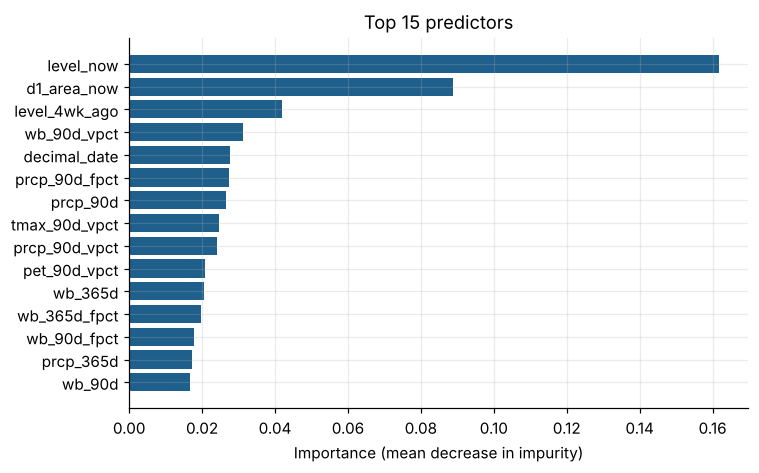

Names: prcp = rainfall, pet = evaporation demand, wb = rainfall minus evaporation, tmax/tmin = temperature;
_90d = 90-day total, _vpct = ranked against the same season, _fpct = ranked against the whole record.


In [7]:
imp = pd.read_csv(USDM_OUT / "rf_importance.csv", index_col=0)["importance"].head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.barh(imp.index, imp.values, color=COLORS["rf_weather_plus_now"]); ax.set_xlabel("Importance (mean decrease in impurity)")
ax.set_title("Top 15 predictors"); plt.tight_layout(); plt.show()
print("Names: prcp = rainfall, pet = evaporation demand, wb = rainfall minus evaporation, tmax/tmin = temperature;")
print("_90d = 90-day total, _vpct = ranked against the same season, _fpct = ranked against the whole record.")

## Part 2: Streamflow drought at stream gauges

Runs once you have real gauge results (`python -m drought_rf --data data/raw --split walk_forward`). Kappa: 0 = no better than chance, 1 = perfect.

In [8]:
f = GAUGE_OUT / "summary.csv"
if not f.exists():
    print("No gauge results yet: run the gauge model first (HOW_TO_USE.md step 4).")
else:
    G = pd.read_csv(f)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    for m, d in G.groupby("model"):
        axes[0].plot(d.lead, d.kappa, marker="o", label=m)
        axes[1].plot(d.lead, d.brier_skill, marker="o", label=m)
    axes[0].set_title("Kappa by lead (days)"); axes[1].set_title("Brier skill vs climatology")
    axes[1].axhline(0, color="#666", lw=.8); axes[0].legend(frameon=False, fontsize=8)
    plt.tight_layout(); plt.show()
    gi = GAUGE_OUT / "rf_importance.csv"
    if gi.exists():
        top = pd.read_csv(gi, index_col=0).mean(axis=1).sort_values().tail(15)
        top.plot.barh(figsize=(7, 4.4), title="Gauge model: top 15 predictors"); plt.tight_layout(); plt.show()

No gauge results yet: run the gauge model first (HOW_TO_USE.md step 4).
